# Kickstarter Project Success: Predicting Funding Before Launch

This notebook takes the Kickstarter dataset from raw data to a tuned machine learning model. It covers the business goal, data cleaning, target leakage, exploratory analysis, baselines, three algorithms with cross-validation, hyperparameter tuning, threshold selection, a final test evaluation, error analysis, and a small data product demo.

**Result in one paragraph.** On 66,335 campaigns the model never saw, the tuned gradient boosting model reaches a **ROC-AUC of 0.765**, compared with 0.629 for a goal-only rule and 0.5 for guessing. At the chosen threshold of 0.32 it finds 83% of successful campaigns (recall 0.83, precision 0.55, F1 0.661). Its probabilities are well calibrated: when it says 60%, about 60% of those campaigns succeed. The strongest drivers are the sub-category, the funding goal, the launch year and the campaign length.

## Define the Business Goal

The stakeholder is a **creator planning a Kickstarter campaign**. Kickstarter uses all-or-nothing funding: if the goal is not reached, the creator gets nothing. Before launching, the creator wants to know how likely the campaign is to succeed, and which choices (goal, duration, category, launch timing) improve the odds.

We predict **whether a project will be successfully funded**, using only information known **at launch time**.

In data science terms this is a **binary classification** problem:

- **Target:** `success` (1 = successful, 0 = failed).
- **Primary metric: ROC-AUC.** The product is a success *probability* for the creator, so we care about how well the model ranks promising and risky projects, independent of any single cut-off. ROC-AUC is also robust to the moderate class imbalance (about 40% successful).
- **Secondary metrics: F1, precision and recall** of the success class at a chosen threshold, because a creator ultimately gets a yes/no style answer. Accuracy is reported for reference only: always predicting "fail" already reaches about 60%.

## Get the Data

Download `ks-projects-201801.csv` from [Kickstarter Projects on Kaggle](https://www.kaggle.com/datasets/kemical/kickstarter-projects) and place it in the `data/` folder. The raw CSV is ignored by git, so every teammate downloads it once.

Without a Kaggle login, the public dataset can also be fetched with `kagglehub`:

```bash
uvx --with kagglehub python -c "import kagglehub; print(kagglehub.dataset_download('kemical/kickstarter-projects'))"
```

Then copy `ks-projects-201801.csv` from the printed folder into `data/`.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

DATA_PATH = Path("data/ks-projects-201801.csv")
MODEL_PATH = Path("models/kickstarter_hgb.joblib")
RANDOM_STATE = 42

# Chart colours: blue = successful, orange = failed, grey = reference lines
SUCCESS_COLOR, FAIL_COLOR, NEUTRAL_COLOR = "#2a78d6", "#eb6834", "#8a8986"
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"{DATA_PATH} not found. Download it from "
        "https://www.kaggle.com/datasets/kemical/kickstarter-projects"
    )

kickstarter = pd.read_csv(DATA_PATH, parse_dates=["deadline", "launched"])
kickstarter.head()

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,0.0,1533.95
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,100.0,2421.0,30000.00
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,220.0,45000.00
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,1.0,5000.00
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29,19500.0,2015-07-04 08:35:03,1283.0,canceled,14,US,1283.0,1283.0,19500.00


### First Look at the Data

In [2]:
print("Shape:", kickstarter.shape)
kickstarter.info()

Shape: (378661, 15)


<class 'pandas.DataFrame'>
RangeIndex: 378661 entries, 0 to 378660
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   ID                378661 non-null  int64         
 1   name              378657 non-null  str           
 2   category          378661 non-null  str           
 3   main_category     378661 non-null  str           
 4   currency          378661 non-null  str           
 5   deadline          378661 non-null  datetime64[us]
 6   goal              378661 non-null  float64       
 7   launched          378661 non-null  datetime64[us]
 8   pledged           378661 non-null  float64       
 9   state             378661 non-null  str           
 10  backers           378661 non-null  int64         
 11  country           378661 non-null  str           
 12  usd pledged       374864 non-null  float64       
 13  usd_pledged_real  378661 non-null  float64       
 14  usd_goal_real  

In [3]:
# Missing values per column
kickstarter.isna().sum()[lambda s: s > 0]

name              4
usd pledged    3797
dtype: int64

The dataset has about 379,000 projects launched between 2009 and early 2018, with 15 columns. Only `name` (4 rows) and `usd pledged` (about 3,800 rows) have missing values. We will drop `usd pledged` anyway (see leakage below).

The columns fall into three groups:

| Group | Columns | Known at launch? |
| --- | --- | --- |
| Identifiers | `ID`, `name` | Yes (`name` can be turned into text features) |
| Project setup | `category`, `main_category`, `currency`, `country`, `goal`, `usd_goal_real`, `launched`, `deadline` | Yes |
| Campaign outcome | `pledged`, `usd pledged`, `usd_pledged_real`, `backers`, `state` | **No**, only after the campaign ends |

## Define the Target

In [4]:
kickstarter["state"].value_counts(dropna=False)

state
failed        197719
successful    133956
canceled       38779
undefined       3562
live            2799
suspended       1846
Name: count, dtype: int64

We keep only finished projects with a clear outcome: `successful` and `failed`.

- `canceled` and `suspended` projects were stopped by the creator or by Kickstarter. Their outcome is not a funding result, and they would blur the target.
- `live` projects had not finished when the data was collected, so their outcome is unknown.
- `undefined` has no usable label.

In [5]:
kickstarter = kickstarter[kickstarter["state"].isin(["successful", "failed"])].copy()
kickstarter["success"] = (kickstarter["state"] == "successful").astype(int)

print("Rows kept:", len(kickstarter))
kickstarter["success"].value_counts(normalize=True).round(3)

Rows kept: 331675


success
0    0.596
1    0.404
Name: proportion, dtype: float64

331,675 projects remain. About 40% succeeded and 60% failed. The imbalance is moderate, so we do not need resampling, but accuracy alone would be misleading.

## Remove Target Leakage

Some columns are only known **after** the campaign ends. A project is successful exactly when it pledges at least its goal, so these columns practically contain the answer:

- `pledged`, `usd pledged`, `usd_pledged_real`: the money raised.
- `backers`: the number of supporters.
- `state`: the raw label we derived the target from.

A creator does not have any of these before launch, so we drop them. The check below shows how strong the leak is.

In [6]:
# How well does "pledged >= goal" reproduce the target?
leak_rule = (kickstarter["usd_pledged_real"] >= kickstarter["usd_goal_real"]).astype(int)
agreement = (leak_rule == kickstarter["success"]).mean()
print("Agreement of pledged >= goal with the target:", round(agreement, 5))

Agreement of pledged >= goal with the target: 0.99997


The simple rule "pledged at least the goal" matches the target for 99.997% of projects. A model trained with these columns would look almost perfect and be useless in practice.

In [7]:
leakage_cols = ["pledged", "usd pledged", "usd_pledged_real", "backers", "state"]

# Also drop columns that carry no extra pre-launch information:
# `ID` is a random identifier, and `goal` is in local currency
# (`usd_goal_real` holds the same goal converted to USD).
redundant_cols = ["ID", "goal"]

kickstarter = kickstarter.drop(columns=leakage_cols + redundant_cols)
kickstarter.columns.tolist()

['name',
 'category',
 'main_category',
 'currency',
 'deadline',
 'launched',
 'country',
 'usd_goal_real',
 'success']

## Clean the Data

In [8]:
print("Countries:", sorted(kickstarter["country"].unique()))
print("Rows with country 'N,0\"':", (kickstarter["country"] == 'N,0"').sum())

Countries: ['AT', 'AU', 'BE', 'CA', 'CH', 'DE', 'DK', 'ES', 'FR', 'GB', 'HK', 'IE', 'IT', 'JP', 'LU', 'MX', 'N,0"', 'NL', 'NO', 'NZ', 'SE', 'SG', 'US']
Rows with country 'N,0"': 210


One country code, `N,0"`, is a scraping error. We relabel those 210 rows as `Unknown` instead of dropping them, so the model can still use their other information. The four missing names become empty strings.

In [9]:
kickstarter["country"] = kickstarter["country"].replace('N,0"', "Unknown")
kickstarter["name"] = kickstarter["name"].fillna("")

## Pre-Launch Features

We derive features that a creator knows before launch. They are fixed per-row transformations (no statistics learned from the data), so it is safe to create them before the split.

| Feature | Meaning |
| --- | --- |
| `log_goal` | The USD goal on a log scale. Goals range from \$0.01 to \$166 million, so the log scale is much easier for models. |
| `duration_days` | Campaign length in calendar days, from the launch date to the deadline date. |
| `launch_year`, `launch_month`, `launch_weekday`, `launch_hour` | When the campaign started. |
| `name_words`, `name_chars` | Length of the project title. |
| `name_has_exclaim`, `name_has_question`, `name_upper_words` | Style of the title: `!`, `?` and words in CAPITALS. |

In [10]:
name = kickstarter["name"]
kickstarter["log_goal"] = np.log1p(kickstarter["usd_goal_real"])
# Count calendar days: `deadline` is a date, `launched` a timestamp, so a plain
# difference would turn the standard 30-day campaign into 29 days.
kickstarter["duration_days"] = (
    kickstarter["deadline"] - kickstarter["launched"].dt.normalize()
).dt.days
kickstarter["launch_year"] = kickstarter["launched"].dt.year
kickstarter["launch_month"] = kickstarter["launched"].dt.month
kickstarter["launch_weekday"] = kickstarter["launched"].dt.dayofweek
kickstarter["launch_hour"] = kickstarter["launched"].dt.hour
kickstarter["name_words"] = name.str.split().str.len()
kickstarter["name_chars"] = name.str.len()
kickstarter["name_has_exclaim"] = name.str.contains("!", regex=False).astype(int)
kickstarter["name_has_question"] = name.str.contains("?", regex=False).astype(int)
kickstarter["name_upper_words"] = name.str.count(r"\b[A-Z]{2,}\b")

CATEGORICAL = ["main_category", "category", "country", "currency"]
NUMERIC = [
    "log_goal", "duration_days", "launch_year", "launch_month", "launch_weekday",
    "launch_hour", "name_words", "name_chars", "name_has_exclaim",
    "name_has_question", "name_upper_words",
]
kickstarter[["usd_goal_real", "duration_days", "name_words"]].describe().round(1)

,usd_goal_real,duration_days,name_words
count,331675.0,331675.0,331675.0
mean,41510.0,34.0,5.6
std,1108929.7,12.7,2.8
min,0.0,1.0,0.0
25%,2000.0,30.0,3.0
50%,5000.0,30.0,5.0
75%,15000.0,36.0,8.0
max,166361390.7,92.0,29.0


Campaigns run between 1 and 92 days, and almost half use exactly 30 days, Kickstarter's suggested default. Half of all goals are \$5,000 or less, but a few are absurdly high (up to \$166 million). We keep these extremes: they are real, almost always fail, and the log scale stops them from dominating.

## Train-Test Split

We hold out 20% of the projects as a test set and do not touch it until the final evaluation. The split is **stratified** on the target, so both sets keep the same share of successful projects.

From here on, anything we *fit* (encoders, scalers, thresholds, models) is learned on the training set only.

In [11]:
from sklearn.model_selection import train_test_split

y = kickstarter["success"]
X = kickstarter[CATEGORICAL + NUMERIC + ["usd_goal_real"]]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| success rate:", round(y_train.mean(), 3))
print("Test: ", X_test.shape, "| success rate:", round(y_test.mean(), 3))

Train: (265340, 16) | success rate: 0.404
Test:  (66335, 16) | success rate: 0.404


In [12]:
# Set the test set aside and save a copy. We do not touch it until the final evaluation.
X_test.to_csv("data/X_test.csv")
y_test.to_csv("data/y_test.csv")

## Explore the Training Data

We look at the success rate across the main levers a creator controls. The dashed line marks the overall success rate.

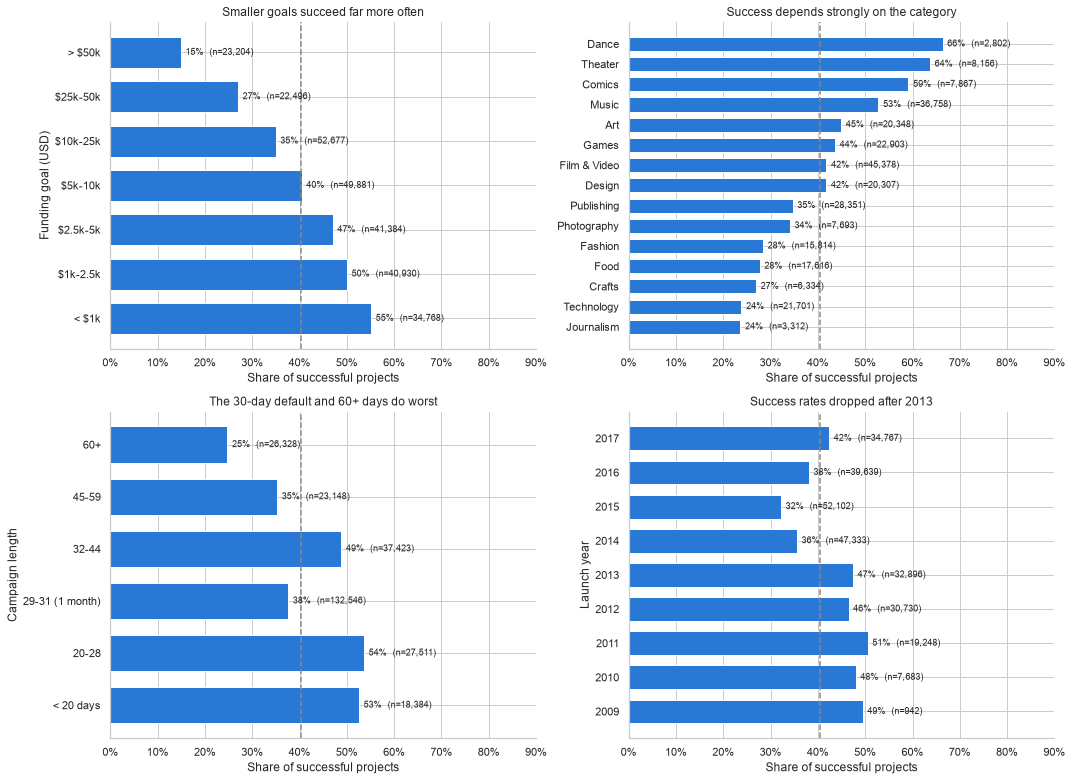

In [13]:
def plot_success_rate(groups, title, ax, xlabel=""):
    """Horizontal bars of the training success rate per group, with sample sizes."""
    stats = y_train.groupby(groups, observed=True).agg(["mean", "size"])
    ax.barh(stats.index.astype(str), stats["mean"], color=SUCCESS_COLOR, height=0.7)
    ax.axvline(y_train.mean(), color=NEUTRAL_COLOR, linestyle="--", linewidth=1.5)
    for i, (rate, n) in enumerate(zip(stats["mean"], stats["size"])):
        ax.text(rate + 0.01, i, f"{rate:.0%}  (n={n:,})", va="center", fontsize=9)
    ax.set(title=title, xlabel="Share of successful projects", ylabel=xlabel, xlim=(0, 0.9))
    ax.xaxis.set_major_formatter("{x:.0%}")
    return stats


goal_bins = [0, 1_000, 2_500, 5_000, 10_000, 25_000, 50_000, np.inf]
goal_labels = ["< $1k", "$1k-2.5k", "$2.5k-5k", "$5k-10k", "$10k-25k", "$25k-50k", "> $50k"]
goal_bucket = pd.cut(X_train["usd_goal_real"], goal_bins, labels=goal_labels, right=False)

duration_bins = [0, 20, 29, 32, 45, 60, 93]
duration_labels = ["< 20 days", "20-28", "29-31 (1 month)", "32-44", "45-59", "60+"]
duration_bucket = pd.cut(X_train["duration_days"], duration_bins, labels=duration_labels, right=False)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
plot_success_rate(goal_bucket, "Smaller goals succeed far more often", axes[0, 0], "Funding goal (USD)")
category_order = y_train.groupby(X_train["main_category"]).mean().sort_values().index
plot_success_rate(
    pd.Categorical(X_train["main_category"], categories=category_order),
    "Success depends strongly on the category", axes[0, 1],
)
plot_success_rate(duration_bucket, "The 30-day default and 60+ days do worst", axes[1, 0], "Campaign length")
plot_success_rate(X_train["launch_year"], "Success rates dropped after 2013", axes[1, 1], "Launch year")
plt.tight_layout()
plt.show()

**What the charts show**

- **Goal:** campaigns asking for less than \$1,000 succeed 55% of the time, those asking for more than \$50,000 only 15%. This is the clearest pattern in the data.
- **Category:** Dance (66%), Theater (64%) and Comics (59%) succeed most often; Technology and Journalism (24% each) least often.
- **Length:** almost half of all campaigns use the 30-day default, and only 38% of those succeed. Campaigns under four weeks reach 53–54% and 32–44-day campaigns 49%, while 60 days or more reach only 25%. So the pattern is not "shorter is better": the default and very long campaigns do worst. This probably reflects how carefully creators plan (a selection effect), not the length itself.
- **Year:** success rates fell sharply in 2014 and 2015, when the number of campaigns jumped, and recovered to 42% by 2017. Because the model uses the launch year, its predictions for new campaigns assume 2017 conditions.

In [14]:
# Countries with at least 1,000 training projects
country_stats = y_train.groupby(X_train["country"]).agg(["mean", "size"])
country_stats[country_stats["size"] >= 1000].sort_values("mean", ascending=False).round(3)

,mean,size
country,,
US,0.418,209099
GB,0.412,23526
FR,0.361,2040
NZ,0.352,1039
SE,0.338,1220
CA,0.336,9846
AU,0.304,5311
MX,0.278,1141
DE,0.273,2752


In [15]:
# Is a large goal the same problem in every category? Median goal by category and outcome.
(
    X_train.assign(outcome=y_train.map({1: "successful", 0: "failed"}))
    .groupby(["main_category", "outcome"])["usd_goal_real"].median()
    .unstack().round(0).sort_values("successful")
)

outcome,failed,successful
main_category,,
Crafts,3000.0,1000.0
Art,3800.0,2000.0
Theater,5000.0,2573.0
Comics,5000.0,2703.0
Photography,4500.0,3000.0
Publishing,5000.0,3000.0
Journalism,5000.0,3000.0
Dance,4627.0,3000.0
Music,5000.0,3200.0


Successful projects ask for much less money than failed ones in **every** category. The goal is the single strongest lever a creator controls. The typical successful goal also varies a lot by category (for example Technology vs. Crafts), which is why the model should combine goal and category rather than use a single global cut-off.

## Baseline Models

Before training a real model we set **baselines**: the simplest rules that make a prediction. Every later model has to beat them.

1. **Always fail:** predict the majority class for every project.
2. **Always succeed:** predict success for every project. This gets perfect recall and shows why F1 on its own can be gamed.
3. **Goal rule:** predict success if the goal is **at or below the median training goal**. For ROC-AUC, the score is the negative goal (smaller goal = more likely to succeed).

In [16]:
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
)


def evaluate(name, y_true, y_pred, y_score):
    """Return the metrics of one model as a dict (one row of the results table)."""
    return {
        "model": name,
        "roc_auc": roc_auc_score(y_true, y_score),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
    }

In [17]:
results = []

# 1. Always fail (majority class). A constant score gives ROC-AUC = 0.5.
always_fail = np.zeros(len(y_test), dtype=int)
results.append(evaluate("Always fail", y_test, always_fail, always_fail))

# 2. Always succeed
always_succeed = np.ones(len(y_test), dtype=int)
results.append(evaluate("Always succeed", y_test, always_succeed, always_succeed))

# 3. Goal rule: threshold learned on the training set only
goal_threshold = X_train["usd_goal_real"].median()
goal_rule = (X_test["usd_goal_real"] <= goal_threshold).astype(int)
results.append(
    evaluate("Goal <= training median", y_test, goal_rule, -X_test["usd_goal_real"])
)

print(f"Median training goal: ${goal_threshold:,.0f}")
baseline_results = pd.DataFrame(results).set_index("model").round(3)
baseline_results

Median training goal: $5,000


,roc_auc,f1,precision,recall,accuracy
model,,,,,
Always fail,0.500,0.000,0.000,0.000,0.596
Always succeed,0.500,0.575,0.404,1.000,0.404
Goal <= training median,0.629,0.545,0.489,0.615,0.585


**How to read the table**

- *Always fail* has 59.6% accuracy but an F1 of 0: it never finds a successful project. That is why accuracy is not our main metric.
- *Always succeed* reaches an F1 of 0.575 with zero skill.
- The *goal rule* is the first baseline with real signal: a ROC-AUC of 0.629. Its F1 (0.545) is actually *below* "always succeed", a good reminder that F1 alone can be gamed.

**The scores to beat:** ROC-AUC 0.629 (goal rule) and F1 0.575 (always succeed).

## Three Algorithms with Cross-Validation

We compare three different kinds of model, each wrapped in a scikit-learn `Pipeline` so that the preprocessing is learned inside each cross-validation fold (no leakage between folds):

1. **Logistic regression:** a linear model. Categories are one-hot encoded (rare categories grouped together), numbers are standardised.
2. **Random forest:** many decision trees on random subsets of rows and features, averaged together.
3. **Histogram gradient boosting:** trees built one after another, each correcting the errors of the previous ones. It handles categorical features natively. We add one piece of domain knowledge as a **monotonic constraint**: all else equal, a higher goal can never *raise* the predicted chance. Without it, the model learned odd bumps for large goals in small categories (where it has few examples), which would make the what-if tool below give illogical advice. The constraint costs only about 0.001 ROC-AUC.

We use 5-fold stratified cross-validation on the training set and compare mean ROC-AUC and F1 (at the default 0.5 threshold).

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

FEATURES = CATEGORICAL + NUMERIC
X_train_model, X_test_model = X_train[FEATURES], X_test[FEATURES]

# Linear model: one-hot categories (rare ones grouped), standardised numbers
linear_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CATEGORICAL),
    ("num", StandardScaler(), NUMERIC),
])

# Tree models: categories as integer codes, numbers unchanged
def tree_preprocessor():
    return ColumnTransformer(
        [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


models = {
    "Logistic regression": make_pipeline(linear_preprocessor, LogisticRegression(max_iter=2000)),
    "Random forest": make_pipeline(
        tree_preprocessor(),
        RandomForestClassifier(
            n_estimators=200, min_samples_leaf=20, max_samples=0.3,
            n_jobs=-1, random_state=RANDOM_STATE,
        ),
    ),
    "Gradient boosting": make_pipeline(
        tree_preprocessor(),
        HistGradientBoostingClassifier(
            categorical_features=CATEGORICAL,
            monotonic_cst={"log_goal": -1},  # higher goal never raises the chance
            random_state=RANDOM_STATE,
        ),
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for model_name, model in models.items():
    scores = cross_validate(model, X_train_model, y_train, cv=cv, scoring=["roc_auc", "f1"])
    cv_rows.append({
        "model": model_name,
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "f1_mean": scores["test_f1"].mean(),
        "fit_seconds": scores["fit_time"].mean(),
    })

cv_results = pd.DataFrame(cv_rows).set_index("model").round(3)
cv_results

,roc_auc_mean,roc_auc_std,f1_mean,fit_seconds
model,,,,
Logistic regression,0.729,0.002,0.552,10.802
Random forest,0.740,0.001,0.544,31.378
Gradient boosting,0.765,0.002,0.605,12.535


Gradient boosting wins clearly: a mean ROC-AUC of **0.765**, against 0.740 for the random forest and 0.729 for logistic regression. The differences are more than ten times larger than the variation between folds (standard deviation about 0.002), so they are not luck. Gradient boosting is also fast (about 12 seconds per fit) and has the best F1 at the default threshold. We tune it next.

## Hyperparameter Tuning

We tune the gradient boosting model with a randomised search: it tries 12 random combinations of settings and scores each with 3-fold cross-validation on the training set.

- `learning_rate`: how big each correction step is.
- `max_leaf_nodes`, `min_samples_leaf`: how complex each tree may get.
- `l2_regularization`: a penalty that keeps the model from over-fitting.
- `max_iter`: the maximum number of trees. Early stopping (on by default for large data) stops sooner when the score stops improving.

In [19]:
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "histgradientboostingclassifier__learning_rate": loguniform(0.03, 0.3),
    "histgradientboostingclassifier__max_leaf_nodes": [15, 31, 63, 127],
    "histgradientboostingclassifier__min_samples_leaf": [20, 50, 100, 200],
    "histgradientboostingclassifier__l2_regularization": [0.0, 0.1, 1.0, 10.0],
    "histgradientboostingclassifier__max_iter": [300, 600, 1000],
}

search = RandomizedSearchCV(
    models["Gradient boosting"],
    param_distributions,
    n_iter=12,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    n_jobs=1,
)
search.fit(X_train_model, y_train)

print("Best cross-validated ROC-AUC:", round(search.best_score_, 4))
{key.split("__")[1]: value for key, value in search.best_params_.items()}

Best cross-validated ROC-AUC: 0.7658


{'l2_regularization': 0.0,
 'learning_rate': np.float64(0.033386559524717176),
 'max_iter': 1000,
 'max_leaf_nodes': 63,
 'min_samples_leaf': 20}

In [20]:
tuning_results = (
    pd.DataFrame(search.cv_results_)
    .sort_values("rank_test_score")
    [["mean_test_score", "std_test_score"] + [c for c in search.cv_results_ if c.startswith("param_")]]
    .rename(columns=lambda c: c.replace("param_histgradientboostingclassifier__", ""))
)
tuning_results.head().round(4)

,mean_test_score,std_test_score,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf
9,0.7658,0.0005,0.0,0.0334,1000,63,20
10,0.7656,0.0007,0.0,0.0348,300,127,50
6,0.7656,0.0008,10.0,0.0316,1000,63,100
7,0.7655,0.0007,0.1,0.0334,1000,31,50
2,0.7653,0.0006,1.0,0.0864,300,127,200


Tuning gives only a small gain: the best combination reaches 0.7658, and the top five combinations are within 0.0005 of each other. The model is not sensitive to its settings, so the remaining limit is the information in the features, not the settings. The chosen model uses a learning rate of about 0.033, up to 1,000 trees, at most 63 leaves per tree and at least 20 projects per leaf.

## Choose the Decision Threshold

A model outputs a probability. To give a yes/no answer we need a **threshold**: above it we predict success. The default of 0.5 is not necessarily the best for our goal.

We choose the threshold on **out-of-fold predictions** of the training set: each training project gets a prediction from a model that never saw it. This keeps the test set untouched. We pick the threshold that maximises F1, the balance of precision and recall.

In [21]:
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_val_predict

best_model = search.best_estimator_
oof_proba = cross_val_predict(
    best_model, X_train_model, y_train,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    method="predict_proba",
)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
f1_scores = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
best_index = np.argmax(f1_scores[:-1])
decision_threshold = thresholds[best_index]

print(f"Out-of-fold ROC-AUC: {roc_auc_score(y_train, oof_proba):.4f}")
print(f"Best threshold: {decision_threshold:.3f}")
print(f"F1 at best threshold: {f1_scores[best_index]:.3f} "
      f"(precision {precision[best_index]:.3f}, recall {recall[best_index]:.3f})")
oof_pred_default = (oof_proba >= 0.5).astype(int)
print(f"F1 at 0.5: {f1_score(y_train, oof_pred_default):.3f}")

Out-of-fold ROC-AUC: 0.7657
Best threshold: 0.318
F1 at best threshold: 0.662 (precision 0.550, recall 0.831)
F1 at 0.5: 0.606


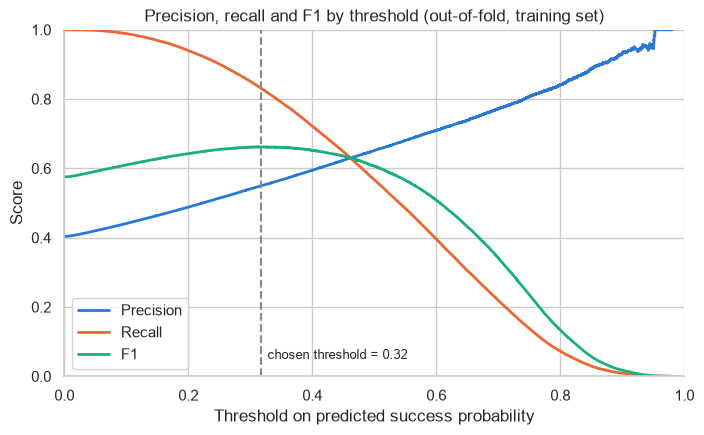

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, precision[:-1], color=SUCCESS_COLOR, linewidth=2, label="Precision")
ax.plot(thresholds, recall[:-1], color=FAIL_COLOR, linewidth=2, label="Recall")
ax.plot(thresholds, f1_scores[:-1], color="#1baf7a", linewidth=2, label="F1")
ax.axvline(decision_threshold, color=NEUTRAL_COLOR, linestyle="--", linewidth=1.5)
ax.text(decision_threshold + 0.01, 0.05, f"chosen threshold = {decision_threshold:.2f}", fontsize=9)
ax.set(title="Precision, recall and F1 by threshold (out-of-fold, training set)",
       xlabel="Threshold on predicted success probability", ylabel="Score", xlim=(0, 1), ylim=(0, 1))
ax.legend()
plt.show()

The best threshold is about **0.32**, raising the out-of-fold F1 from 0.606 (at 0.5) to 0.662. A lower threshold means we call more campaigns "likely to succeed": the model finds 83% of the successful ones (recall), and 55% of its "success" calls are right (precision).

For the creator tool we show the probability itself; the threshold only matters for a yes/no label. A stakeholder who wants to avoid giving false hope would choose a higher threshold (more precision, less recall).

## Final Evaluation on the Test Set

Now, and only now, we use the held-out test set. The tuned model is refitted on the full training set (done by `RandomizedSearchCV`) and evaluated with the threshold chosen above.

In [23]:
test_proba = best_model.predict_proba(X_test_model)[:, 1]
test_pred = (test_proba >= decision_threshold).astype(int)

final_results = pd.concat([
    baseline_results,
    pd.DataFrame([evaluate("Tuned gradient boosting", y_test, test_pred, test_proba)]).set_index("model"),
]).round(3)
final_results

,roc_auc,f1,precision,recall,accuracy
model,,,,,
Always fail,0.500,0.000,0.000,0.000,0.596
Always succeed,0.500,0.575,0.404,1.000,0.404
Goal <= training median,0.629,0.545,0.489,0.615,0.585
Tuned gradient boosting,0.765,0.661,0.549,0.831,0.656


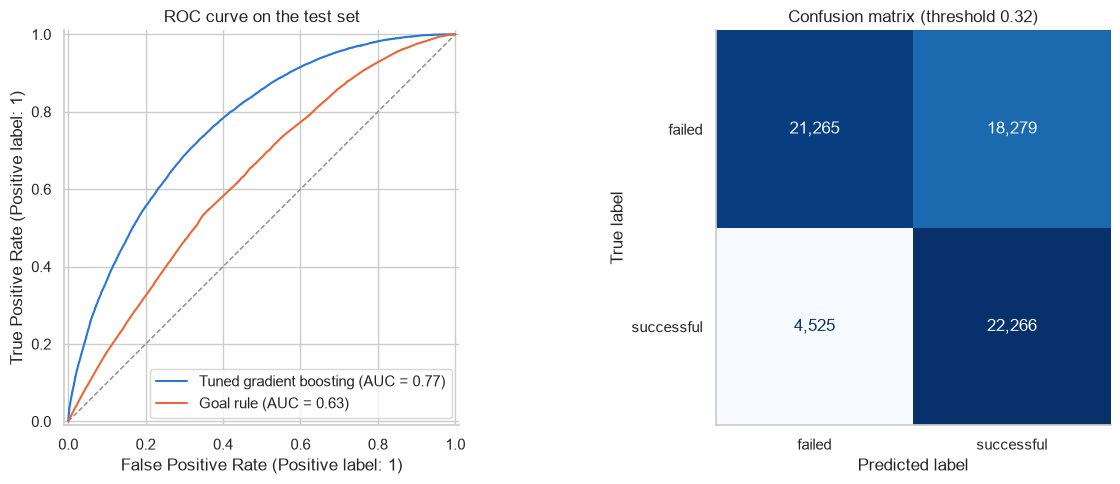

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for scores, label, color in [
    (test_proba, "Tuned gradient boosting", SUCCESS_COLOR),
    (-X_test["usd_goal_real"], "Goal rule", FAIL_COLOR),
]:
    RocCurveDisplay.from_predictions(y_test, scores, name=label, ax=axes[0])
    axes[0].lines[-1].set_color(color)
axes[0].legend()
axes[0].plot([0, 1], [0, 1], color=NEUTRAL_COLOR, linestyle="--", linewidth=1)
axes[0].set_title("ROC curve on the test set")

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["failed", "successful"],
    cmap="Blues", values_format=",", ax=axes[1], colorbar=False,
)
axes[1].set_title(f"Confusion matrix (threshold {decision_threshold:.2f})")
axes[1].grid(False)
plt.tight_layout()
plt.show()

**The final exam.** On the untouched test set, the tuned model reaches a ROC-AUC of **0.765**, the same as in cross-validation, so it did not over-fit. It beats every baseline on every metric except recall (where "always succeed" is trivially perfect):

- ROC-AUC 0.765 vs. 0.629 for the goal rule.
- F1 0.661 vs. 0.575 for "always succeed".

In the confusion matrix: of 26,791 successful test campaigns the model correctly flags 22,266 (83%). The price is 18,279 failed campaigns that it also called "likely to succeed": about 45% of its success calls are false hope.

## Error Analysis

Where does the model go wrong? We analyse the **out-of-fold predictions on the training set**, so the test set stays a clean final check. We look at:

1. Performance by segment (category, goal size, country).
2. Calibration: when the model says "60%", do about 60% of those projects succeed?
3. The most confident mistakes.
4. Which features the model relies on.

In [25]:
analysis = X_train.assign(
    success=y_train,
    proba=oof_proba,
    pred=(oof_proba >= decision_threshold).astype(int),
    goal_bucket=goal_bucket,
)
analysis["correct"] = analysis["pred"] == analysis["success"]


def segment_report(column):
    """ROC-AUC, accuracy and success rate per segment of the out-of-fold predictions."""
    return (
        analysis.groupby(column, observed=True)
        .apply(lambda g: pd.Series({
            "projects": len(g),
            "success_rate": g["success"].mean(),
            "roc_auc": roc_auc_score(g["success"], g["proba"]) if g["success"].nunique() > 1 else np.nan,
            "accuracy": g["correct"].mean(),
        }), include_groups=False)
        .round(3)
    )


segment_report("main_category").sort_values("roc_auc")

,projects,success_rate,roc_auc,accuracy
main_category,,,,
Dance,2802.0,0.663,0.702,0.706
Theater,8156.0,0.637,0.710,0.684
Photography,7693.0,0.341,0.714,0.637
Design,20307.0,0.418,0.717,0.606
Art,20348.0,0.449,0.719,0.612
Journalism,3312.0,0.236,0.719,0.729
Film & Video,45378.0,0.418,0.720,0.610
Publishing,28351.0,0.347,0.721,0.637
Fashion,15814.0,0.284,0.722,0.683


In [26]:
segment_report("goal_bucket")

,projects,success_rate,roc_auc,accuracy
goal_bucket,,,,
< $1k,34768.0,0.551,0.724,0.633
$1k-2.5k,40930.0,0.500,0.731,0.627
$2.5k-5k,41384.0,0.470,0.730,0.622
$5k-10k,49881.0,0.404,0.735,0.626
$10k-25k,52677.0,0.349,0.737,0.647
$25k-50k,22496.0,0.270,0.752,0.708
> $50k,23204.0,0.149,0.828,0.849


In [27]:
country_report = segment_report("country")
country_report[country_report["projects"] >= 1000].sort_values("roc_auc")

,projects,success_rate,roc_auc,accuracy
country,,,,
MX,1141.0,0.278,0.714,0.663
SE,1220.0,0.338,0.732,0.652
NL,1968.0,0.253,0.758,0.725
US,209099.0,0.418,0.760,0.649
CA,9846.0,0.336,0.771,0.684
FR,2040.0,0.361,0.773,0.677
DE,2752.0,0.273,0.773,0.717
GB,23526.0,0.412,0.774,0.668
AU,5311.0,0.304,0.781,0.709


**Performance by segment**

- **Category:** ROC-AUC ranges from 0.70 (Dance) to 0.83 (Technology). The model is weakest in the arts categories with high success rates, where success depends on the content and the community, which our data does not describe.
- **Goal:** the model is best for large goals (ROC-AUC 0.83 above \$50,000), where failure is easy to spot, and weaker for small goals (about 0.72–0.73), where most campaigns look alike on paper.
- **Country:** every country with at least 1,000 projects scores between 0.71 (Mexico) and 0.82 (Italy). No country is badly served.

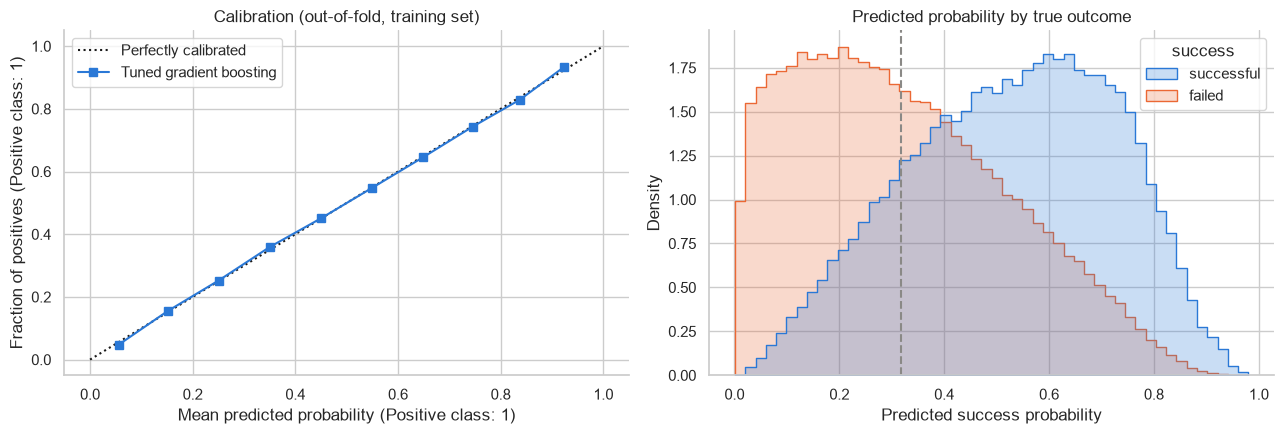

In [28]:
from sklearn.calibration import CalibrationDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
CalibrationDisplay.from_predictions(
    y_train, oof_proba, n_bins=10, name="Tuned gradient boosting", ax=axes[0]
)
axes[0].lines[-1].set_color(SUCCESS_COLOR)
axes[0].legend()
axes[0].set_title("Calibration (out-of-fold, training set)")

sns.histplot(
    x=oof_proba, hue=y_train.map({1: "successful", 0: "failed"}),
    palette={"successful": SUCCESS_COLOR, "failed": FAIL_COLOR},
    bins=50, stat="density", common_norm=False, element="step", ax=axes[1],
)
axes[1].axvline(decision_threshold, color=NEUTRAL_COLOR, linestyle="--", linewidth=1.5)
axes[1].set(title="Predicted probability by true outcome", xlabel="Predicted success probability")
plt.tight_layout()
plt.show()

**Calibration:** the model's curve lies almost exactly on the diagonal. Its probabilities can be taken literally: of the campaigns it gives 60%, about 60% succeed. This is what makes the probability useful for creators.

**Overlap:** the two distributions overlap a lot. Many failed campaigns look exactly like successful ones in our data. This is the limit of pre-launch information: the quality of the idea, the video and the creator's network are not in the dataset.

In [29]:
# The most confident mistakes
show_cols = ["main_category", "category", "country", "usd_goal_real", "duration_days", "launch_year", "proba"]
confident_false_positive = analysis[analysis["success"] == 0].nlargest(5, "proba")[show_cols]
confident_false_negative = analysis[analysis["success"] == 1].nsmallest(5, "proba")[show_cols]
print("Predicted success, but failed:")
display(confident_false_positive.round(3))
print("Predicted failure, but succeeded:")
display(confident_false_negative.round(3))

Predicted success, but failed:


,main_category,category,country,usd_goal_real,duration_days,launch_year,proba
342262,Games,Tabletop Games,FR,893.44,29,2016,0.952
188127,Games,Tabletop Games,US,75.00,12,2016,0.951
56149,Games,Tabletop Games,US,500.00,21,2016,0.951
63444,Games,Tabletop Games,US,3000.00,13,2017,0.950
373020,Games,Tabletop Games,US,100.00,8,2016,0.947


Predicted failure, but succeeded:


,main_category,category,country,usd_goal_real,duration_days,launch_year,proba
301390,Technology,Apps,US,38000.00,60,2016,0.009
324905,Food,Restaurants,CA,78492.94,60,2015,0.011
20016,Food,Food,GB,257069.41,30,2017,0.012
114585,Technology,Technology,SE,243664.72,30,2017,0.014
157978,Technology,Apps,US,60000.00,40,2015,0.014


**The most confident mistakes**

- **Predicted success, but failed:** all five are tabletop games with tiny goals (\$75 to \$3,000) and short campaigns. On paper they are perfect campaigns, but something we cannot see went wrong: no promotion, a weak product, or a hobby project that was never pushed.
- **Predicted failure, but succeeded:** large goals (\$38,000 to \$257,000) in Technology and Food, often with long campaigns. These are exceptional projects, probably with an existing audience or press coverage.

Both groups point to the same missing information: the creator's track record and audience, the campaign page (video, rewards, description) and marketing.

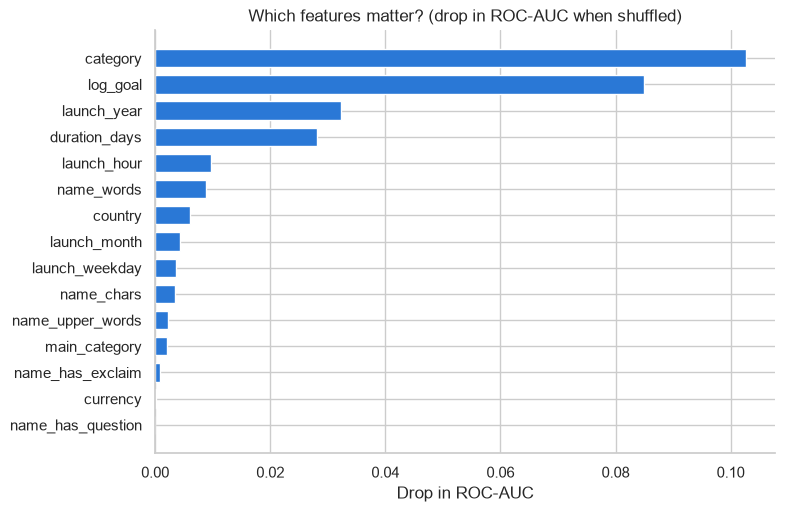

category             0.1026
log_goal             0.0849
launch_year          0.0323
duration_days        0.0281
launch_hour          0.0098
name_words           0.0088
country              0.0060
launch_month         0.0042
launch_weekday       0.0037
name_chars           0.0035
name_upper_words     0.0023
main_category        0.0021
name_has_exclaim     0.0008
currency             0.0002
name_has_question    0.0000
dtype: float64

In [30]:
from sklearn.inspection import permutation_importance

# Permutation importance: how much does test ROC-AUC drop when one feature is shuffled?
sample = X_test_model.sample(20_000, random_state=RANDOM_STATE)
importance = permutation_importance(
    best_model, sample, y_test.loc[sample.index],
    scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE,
)
feature_importance = (
    pd.Series(importance.importances_mean, index=FEATURES).sort_values()
)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(feature_importance.index, feature_importance.values, color=SUCCESS_COLOR, height=0.7)
ax.set(title="Which features matter? (drop in ROC-AUC when shuffled)", xlabel="Drop in ROC-AUC")
plt.show()
feature_importance.sort_values(ascending=False).round(4)

**What the model relies on**

- The sub-**category** (0.103) and the **goal** (0.085) dominate: shuffling either costs the model about 0.09–0.10 ROC-AUC.
- The **launch year** (0.032) and the **campaign length** (0.028) follow.
- Title features, launch hour, weekday and month add only a little. `currency` adds nothing (it duplicates `country`), and `main_category` adds little because `category` already contains it.

## Data Product Demo: a Pre-Launch Campaign Checker

The model can power a simple tool: a creator enters their planned campaign and gets a success probability, plus "what if" suggestions. Below, an example US board game project launched in October 2017: how does the chance change with the goal and the campaign length?

In [31]:
def campaign_checker(**project):
    """Return the predicted success probability for one planned campaign."""
    project.setdefault("log_goal", np.log1p(project.pop("usd_goal")))
    row = pd.DataFrame([project])[FEATURES]
    return best_model.predict_proba(row)[0, 1]


example = {
    "main_category": "Games", "category": "Tabletop Games", "country": "US", "currency": "USD",
    "duration_days": 30, "launch_year": 2017, "launch_month": 10, "launch_weekday": 1,
    "launch_hour": 15, "name_words": 5, "name_chars": 32, "name_has_exclaim": 0,
    "name_has_question": 0, "name_upper_words": 0,
}

what_if = pd.DataFrame(
    [
        {"goal_usd": goal, "duration_days": days,
         "success_probability": campaign_checker(**{**example, "usd_goal": goal, "duration_days": days})}
        for goal in [5_000, 10_000, 20_000, 50_000]
        for days in [21, 30, 45, 60]
    ]
)
what_if.pivot(index="goal_usd", columns="duration_days", values="success_probability").round(2)

duration_days,21,30,45,60
goal_usd,,,,
5000,0.93,0.80,0.70,0.52
10000,0.92,0.77,0.66,0.47
20000,0.88,0.69,0.63,0.37
50000,0.83,0.62,0.56,0.27


For this board game, the levers are large. At \$5,000 and 21 days the model estimates 93%; at \$50,000 and 60 days only 27%. At the 30-day default, raising the goal from \$5,000 to \$50,000 lowers the chance from 80% to 62%. Short campaigns look best here, but this mostly reflects who runs them (experienced creators), so treat duration as a pattern, not a lever.

**Caveat:** the model describes patterns in past campaigns, not causes. It can tell a creator "campaigns like yours succeeded this often", not "shortening your campaign *will* raise your chance by 13 points".

In [32]:
# Save the tuned model and the decision threshold for later use
joblib.dump({"model": best_model, "threshold": decision_threshold, "features": FEATURES}, MODEL_PATH)
print("Saved to", MODEL_PATH)

Saved to models\kickstarter_hgb.joblib


## Conclusions and Future Work

**Conclusions**

1. Using only information known before launch, the model ranks campaigns far better than simple rules: ROC-AUC 0.765 vs. 0.629 for the goal rule, with well-calibrated probabilities.
2. The levers a creator controls matter: a modest goal goes with much higher success rates, while the 30-day default and 60+ day campaigns do worst.
3. Pre-launch data has a clear limit: many failed and successful campaigns look identical on paper, so the model gives chances, not certainties.

**Recommendations for creators**

- Set the lowest goal that really funds the project, and use stretch goals for extras.
- Choose the campaign length on purpose instead of keeping the 30-day default; avoid 60 days.
- Be realistic in hard categories (Technology, Food, Fashion, Journalism): build an audience before launch.

**Future work** (the first two were checked in a quick independent review)

- **Title text:** a TF-IDF model on the project title, stacked into the gradient boosting model, raised 3-fold CV ROC-AUC from 0.765 to 0.782, the largest gain found.
- **Time-based check:** training on 2009–2016 and testing on 2017 gave ROC-AUC 0.779, so the model holds up on newer campaigns, but it under-predicts 2017 success by about 2 points.

- **More data:** creator history, description text, reward tiers, video and social media reach, to explain the overlap.
- **Time-based validation:** train on older campaigns and test on the newest, to measure how well the model works on future campaigns. Refresh the data, since it ends in early 2018.
- **Text models:** use the title and description with NLP.
- **Deployment:** offer the campaign checker as a web tool and monitor its accuracy over time.

## References & Further Reading

- [**Kickstarter Projects (Kaggle)**](https://www.kaggle.com/datasets/kemical/kickstarter-projects): the dataset used here.
- [**HistGradientBoostingClassifier (scikit-learn)**](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html): the final model.
- [**RandomizedSearchCV (scikit-learn)**](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html): hyperparameter tuning.
- [**Permutation importance (scikit-learn)**](https://scikit-learn.org/stable/modules/permutation_importance.html): how the feature importances are computed.
- [**Common pitfalls and recommended practices (scikit-learn)**](https://scikit-learn.org/stable/common_pitfalls.html): data leakage and how to avoid it.